In [63]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.optimizers import Adam
import matplotlib.pyplot as plt
from keras.applications.vgg19 import VGG19
from keras import ops

In [64]:
# Define Functions For Dispaying And Pre-Processing Images
def preprocess(img):
  img = tf.io.read_file(img)
  img = tf.image.decode_image(img)
  img = tf.cast(img, dtype=tf.float32)
  img = tf.expand_dims(img, axis=0)
  img = tf.image.resize(img, (256, 256))
  return img

def display(img):
  img = np.array(img)
  img = np.clip(img, 0, 255).astype("uint8")
  if len(img.shape) == 4:
    img = np.squeeze(img)

  plt.figure(figsize=(10, 5))
  plt.axis("off")
  plt.imshow(img)
  plt.show()


In [65]:
# Download VGG19 Neural Net
model = VGG19(include_top=False, weights="imagenet")
model.trainable = False
model.summary()

Model: "vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 20,024,384 (76.39 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 20,024,384 (76.39 MB)

In [66]:
# Define Gram Matrix Function For Capturing "Style"
def gram_matrix(A):
  gram = ops.einsum("bijc,bijd->bcd", A, A)
  shape = ops.shape(A)
  i_j = ops.cast(ops.size(A[0, :, :, 0]), A.dtype)

  return gram/i_j

In [67]:
# Function To Extract "Style" and "Content" From Model Outputs
content_layer = "block4_conv1"

style_layers = [
    "block1_conv1" ,
    "block2_conv1" ,
    "block3_conv1" ,
    "block4_conv1" ,
    "block5_conv1" ,
    ]

def create_model():
  content_output = model.get_layer(content_layer).output
  style_outputs = [model.get_layer(style_layer).output for style_layer in style_layers]
  gram_outputs = [gram_matrix(output) for output in style_outputs]

  extractor = keras.Model(inputs=[model.input], outputs=[content_output, gram_outputs])
  return extractor

In [68]:
# Load Content And Style Images
C_img = "images/rabbit.png"
S_img = "images/starry.png"

content = preprocess(C_img)
style = preprocess(S_img)

content.shape, style.shape, style.dtype

(TensorShape([1, 256, 256, 3]), TensorShape([1, 256, 256, 3]), tf.float32)

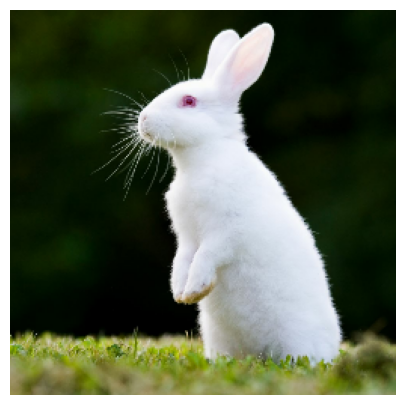

In [69]:
display(content)

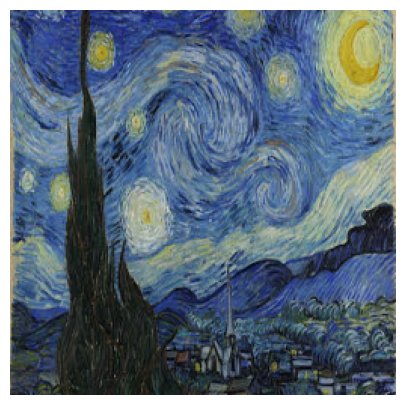

In [70]:
display(style)

In [71]:
# Extract Content And Style From Images
extractor = create_model()
C = extractor(content)[0]
a_S = extractor(style)[1]

In [72]:
# Define Loss Function
wpl = 1/len(style_layers) # normalization factor
def loss(a_G, a_S, G, C, w_1, w_2):
  style_loss = tf.add_n([tf.reduce_mean((G - S)**2) for G, S in zip(a_G, a_S)])/wpl
  content_loss = tf.reduce_mean((G - C)**2)
  total_loss = w_1*content_loss + w_2*style_loss

  return total_loss

In [73]:
# Define Train Function
def train(img, epoch, w_1 = 1e-4, w_2=1e-2):
  opt = Adam(learning_rate=0.2, beta_1=0.99)
  for i in range(epoch):
    with tf.GradientTape() as tape:
      outputs = extractor(img)
      total_loss = loss(outputs[1], a_S, outputs[0], C, w_1, w_2)
      print(f"Epoch: {i}")
      print(f"Loss: {total_loss}")

    grads = tape.gradient(total_loss, img)
    opt.apply_gradients([(grads, img)])
  return img

In [74]:
# Training
generated = tf.Variable(content, dtype=tf.float32)
result = train(generated, epoch = 500)

Epoch: 0
Loss: 5960473600.0
Epoch: 1
Loss: 5748931584.0
Epoch: 2
Loss: 5548452864.0
Epoch: 3
Loss: 5357133312.0
Epoch: 4
Loss: 5173777920.0
Epoch: 5
Loss: 4997813248.0
Epoch: 6
Loss: 4828418560.0
Epoch: 7
Loss: 4664742400.0
Epoch: 8
Loss: 4506916352.0
Epoch: 9
Loss: 4354702336.0
Epoch: 10
Loss: 4208371968.0
Epoch: 11
Loss: 4067719168.0
Epoch: 12
Loss: 3932136960.0
Epoch: 13
Loss: 3801864960.0
Epoch: 14
Loss: 3676538624.0
Epoch: 15
Loss: 3555493376.0
Epoch: 16
Loss: 3438652416.0
Epoch: 17
Loss: 3325911552.0
Epoch: 18
Loss: 3217209600.0
Epoch: 19
Loss: 3112371456.0
Epoch: 20
Loss: 3011094016.0
Epoch: 21
Loss: 2913154048.0
Epoch: 22
Loss: 2818614784.0
Epoch: 23
Loss: 2727288320.0
Epoch: 24
Loss: 2639201024.0
Epoch: 25
Loss: 2554216704.0
Epoch: 26
Loss: 2472299520.0
Epoch: 27
Loss: 2393123072.0
Epoch: 28
Loss: 2316845056.0
Epoch: 29
Loss: 2243420416.0
Epoch: 30
Loss: 2172723712.0
Epoch: 31
Loss: 2104825600.0
Epoch: 32
Loss: 2039683584.0
Epoch: 33
Loss: 1977214848.0
Epoch: 34
Loss: 19172885

/tmp/ipykernel_1468/1058286420.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  img = np.array(img)


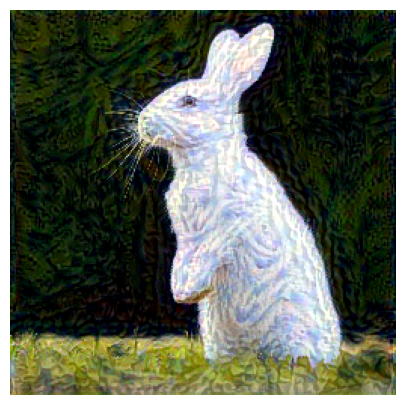

In [75]:
# Style Transferred
display(result)